In [ ]:
import pandas as pd
df = pd.read_csv("data.csv")
df.head()

,track_id,track_name,artists,popularity,release_year,track_genre,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,duration_ms,lyrics
0,6f807x0ima9a1j3VPbc7VN,I Don't Care (with Justin Bieber) - Loud Luxur...,Ed Sheeran,66,2019,dance pop,0.748,0.916,6,-2.634,1.0,0.0583,0.1020,0.000000,0.0653,0.518,122.036,194754.0,[Verse 1: Ed Sheeran]\nI'm at a party I don't ...
1,0r7CVbZTWZgbTCYdfa2P31,Memories - Dillon Francis Remix,Maroon 5,67,2019,dance pop,0.726,0.815,11,-4.969,1.0,0.0373,0.0724,0.004210,0.3570,0.693,99.972,162600.0,[Chorus]\nHere's to the ones that we got\nChee...
2,1z1Hg7Vb0AhHDiEmnDE79l,All the Time - Don Diablo Remix,Zara Larsson,70,2019,dance pop,0.675,0.931,1,-3.432,0.0,0.0742,0.0794,0.000023,0.1100,0.613,124.008,176616.0,[Intro]\nFrom the breaking of the day to the m...
3,75FpbthrwQmzHlBJLuGdC7,Call You Mine - Keanu Silva Remix,The Chainsmokers,60,2019,dance pop,0.718,0.930,7,-3.778,1.0,0.1020,0.0287,0.000009,0.2040,0.277,121.956,169093.0,[Verse 1]\nTwo kids with their hearts on fire\...
4,1e8PAfcKUYoKkxPhrHqw4x,Someone You Loved - Future Humans Remix,Lewis Capaldi,69,2019,dance pop,0.650,0.833,1,-4.672,1.0,0.0359,0.0803,0.000000,0.0833,0.725,123.976,189052.0,"[Verse 1]\nI'm going under, and this time, I f..."


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

def display_df(df: pd.DataFrame, n: int = 5):
    try:
        from IPython.display import display
        display(df.head(n))
    except Exception:
        print(df.head(n))

def full_overview(df: pd.DataFrame, sample_rows: int = 5) -> None:
    print('Shape:', df.shape)
    print('\nColumns and dtypes:')
    print(df.dtypes)
    print('\nFirst rows:')
    display_df(df, n=sample_rows)
    print('\nBasic describe (numerical):')
    display_df(df.describe().T, n=20)
    print('\nUnique counts (top 50):')
    display_df(df.nunique().sort_values(ascending=False).to_frame('nunique'), n=50)

def missing_summary(df: pd.DataFrame, show_plot: bool = True) -> pd.DataFrame:
    miss = df.isnull().sum()
    miss_pct = 100 * miss / len(df)
    table = pd.DataFrame({'missing_count': miss, 'missing_pct': miss_pct}).sort_values('missing_pct', ascending=False)
    if show_plot:
        plt.figure(figsize=(10, 6))
        sns.barplot(x=table['missing_pct'].values[:40], y=table.index[:40])
        plt.xlabel('missing %')
        plt.title('Top 40 columns by missing percent')
        plt.show()
    return table


def top_value_counts(df: pd.DataFrame, col: str, top_n: int = 20) -> pd.Series:
    return df[col].value_counts(dropna=False).head(top_n)

In [ ]:
full_overview(df)

Shape: (35230, 19)

Columns and dtypes:
track_id             object
track_name           object
artists              object
popularity            int64
release_year        float64
track_genre          object
danceability        float64
energy              float64
key                   int64
loudness            float64
mode                  int64
speechiness         float64
acousticness        float64
instrumentalness    float64
liveness            float64
valence             float64
tempo               float64
duration_ms           int64
lyrics               object
dtype: object

First rows:


,track_id,track_name,artists,popularity,release_year,track_genre,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,duration_ms,lyrics
0,6f807x0ima9a1j3VPbc7VN,I Don't Care (with Justin Bieber) - Loud Luxur...,Ed Sheeran,66,2019.0,dance pop,0.748,0.916,6,-2.634,1,0.0583,0.1020,0.000000,0.0653,0.518,122.036,194754,[Verse 1: Ed Sheeran]\nI'm at a party I don't ...
1,0r7CVbZTWZgbTCYdfa2P31,Memories - Dillon Francis Remix,Maroon 5,67,2019.0,dance pop,0.726,0.815,11,-4.969,1,0.0373,0.0724,0.004210,0.3570,0.693,99.972,162600,[Chorus]\nHere's to the ones that we got\nChee...
2,1z1Hg7Vb0AhHDiEmnDE79l,All the Time - Don Diablo Remix,Zara Larsson,70,2019.0,dance pop,0.675,0.931,1,-3.432,0,0.0742,0.0794,0.000023,0.1100,0.613,124.008,176616,[Intro]\nFrom the breaking of the day to the m...
3,75FpbthrwQmzHlBJLuGdC7,Call You Mine - Keanu Silva Remix,The Chainsmokers,60,2019.0,dance pop,0.718,0.930,7,-3.778,1,0.1020,0.0287,0.000009,0.2040,0.277,121.956,169093,[Verse 1]\nTwo kids with their hearts on fire\...
4,1e8PAfcKUYoKkxPhrHqw4x,Someone You Loved - Future Humans Remix,Lewis Capaldi,69,2019.0,dance pop,0.650,0.833,1,-4.672,1,0.0359,0.0803,0.000000,0.0833,0.725,123.976,189052,"[Verse 1]\nI'm going under, and this time, I f..."



Basic describe (numerical):


,count,mean,std,min,25%,50%,75%,max
popularity,35230.0,41.250809,27.249826,0.00000,17.000000,47.000000,64.00000,100.000
release_year,35230.0,2007.207834,31.965994,1.00000,2001.000000,2014.000000,2019.00000,2025.000
danceability,35230.0,0.594289,0.162696,0.06290,0.485000,0.601000,0.71400,0.980
energy,35230.0,0.694851,0.201876,0.00002,0.557000,0.720000,0.86300,1.000
key,35230.0,5.366903,3.588436,0.00000,2.000000,6.000000,9.00000,11.000
loudness,35230.0,-6.845577,3.074636,-34.28300,-8.393000,-6.227000,-4.66800,1.023
mode,35230.0,0.614987,0.486605,0.00000,0.000000,1.000000,1.00000,1.000
speechiness,35230.0,0.091762,0.089865,0.02230,0.037100,0.054700,0.10300,0.914
acousticness,35230.0,0.190197,0.249782,0.00000,0.007900,0.071350,0.28400,0.996
instrumentalness,35230.0,0.051544,0.164104,0.00000,0.000000,0.000014,0.00251,0.993



Unique counts (top 50):


,nunique
track_id,28070
lyrics,22120
track_name,21756
duration_ms,19216
tempo,18811
loudness,10077
artists,8471
instrumentalness,4708
acousticness,4217
liveness,1609


release year 1 is not normal

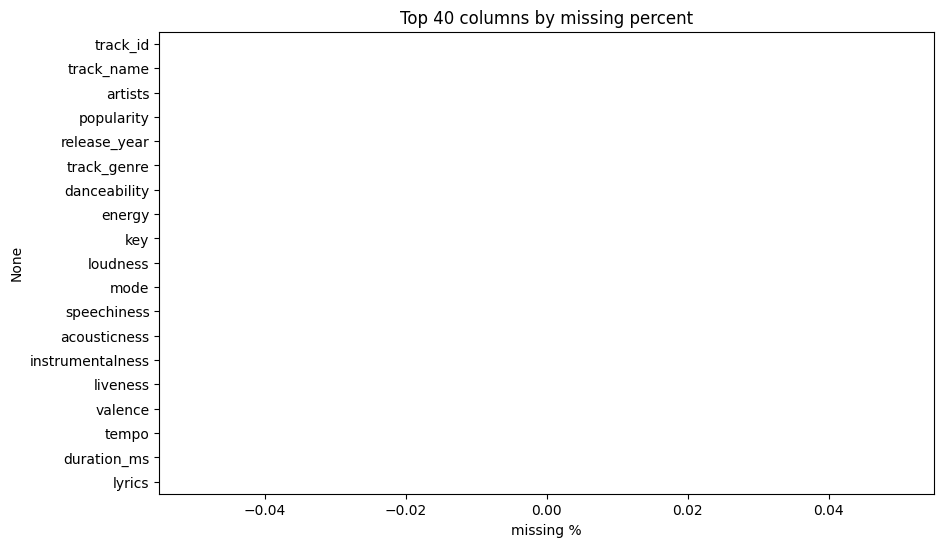

,missing_count,missing_pct
track_id,0,0.0
track_name,0,0.0
artists,0,0.0
popularity,0,0.0
release_year,0,0.0
track_genre,0,0.0
danceability,0,0.0
energy,0,0.0
key,0,0.0
loudness,0,0.0


In [ ]:
missing_summary(df)

No missing data

[I 2025-10-04 04:31:56,163] A new study created in memory with name: no-name-086d85eb-23ca-4fd1-9d31-05ce87d708c3
[I 2025-10-04 04:32:20,187] Trial 0 finished with value: 0.1957670560505551 and parameters: {'n_estimators': 600, 'learning_rate': 0.074956617979145, 'subsample': 0.8850970220784842, 'colsample_bytree': 0.8643119848562579, 'max_depth': 4}. Best is trial 0 with value: 0.1957670560505551.
[I 2025-10-04 04:32:45,202] Trial 1 finished with value: 0.1967298343437411 and parameters: {'n_estimators': 1000, 'learning_rate': 0.011750847064322714, 'subsample': 0.7947366291608833, 'colsample_bytree': 0.5516321081292144, 'max_depth': 5}. Best is trial 1 with value: 0.1967298343437411.
[I 2025-10-04 04:32:51,480] Trial 2 finished with value: 0.19803554338385906 and parameters: {'n_estimators': 200, 'learning_rate': 0.09914835676090508, 'subsample': 0.7446977912041307, 'colsample_bytree': 0.5365531491663329, 'max_depth': 5}. Best is trial 2 with value: 0.19803554338385906.
[I 2025-10-04 

[2025-10-04 05:13:11] Optuna best LightGBM params: {'n_estimators': 2000, 'learning_rate': 0.005924898888182545, 'subsample': 0.5791127131454405, 'colsample_bytree': 0.9937741994787826, 'max_depth': 8}
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.044359 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 32967
[LightGBM] [Info] Number of data points in the train set: 20928, number of used features: 297
[LightGBM] [Info] Start training from score 42.642106
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[Li

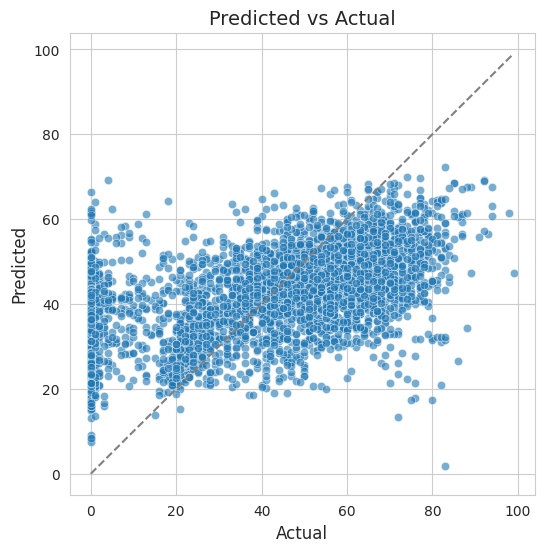

In [2]:
!pip install -q optuna
import os
import random
import time
import warnings

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import math

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, PolynomialFeatures
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestRegressor, StackingRegressor
from sklearn.neural_network import MLPRegressor
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import cross_val_score, train_test_split, KFold
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.inspection import permutation_importance

import lightgbm as lgb
import xgboost as xgb
import optuna

def set_plot_style():
    sns.set_style('whitegrid')
    plt.rcParams['figure.figsize'] = (8, 5)
    plt.rcParams['axes.titlesize'] = 14
    plt.rcParams['axes.labelsize'] = 12

def plot_predicted_vs_actual(y_true: np.ndarray, y_pred: np.ndarray) -> None:
    set_plot_style()
    plt.figure(figsize=(6,6))
    sns.scatterplot(x=y_true, y=y_pred, alpha=0.6)
    lims = [min(min(y_true), min(y_pred)), max(max(y_true), max(y_pred))]
    plt.plot(lims, lims, '--', color='gray')
    plt.xlabel('Actual'); plt.ylabel('Predicted'); plt.title('Predicted vs Actual')
    plt.show()

def regression_metrics(y_true, y_pred):
    return {
        'rmse': math.sqrt(mean_squared_error(y_true, y_pred)),
        'mae': mean_absolute_error(y_true, y_pred),
        'r2': r2_score(y_true, y_pred)
    }

warnings.filterwarnings('ignore')

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

df = pd.read_csv("data.csv")

#Change year 21 to 2021
df.release_year[df.release_year == 21.0] = 2021

#Drop outlier year
df = df[df.release_year != 1.0]

#Drop duplicate songs by the same artists
df = df.drop_duplicates(
  subset = ['track_name', 'artists', 'release_year'],
  keep = 'last').reset_index(drop = True)

#Convert year to datetime
df['year'] = pd.to_datetime(df['release_year']).dt.dayofyear

#Feature engineer using sin and cos
df['y_sin'] = np.sin(2*np.pi*df['year']/365)
df['y_cos'] = np.cos(2*np.pi*df['year']/365)

#Define features and target
features = ['release_year', 'danceability', 'energy', 'key', 'loudness', 'mode', 'speechiness', 'acousticness', 'instrumentalness', 'liveness', 'valence', 'tempo', 'duration_ms', 'y_sin', 'y_cos']
target = 'popularity'

#Split into train and test
df_train, df_test = train_test_split(df, test_size=0.15, random_state=42)

#Split into X, y (train) and X_test, y_test (test)
X = df_train.drop(columns=target)
y = df_train[target].values
X_test = df_test.drop(columns=target)
y_test = df_test[target].values

#Make pipeline
num_cols = X.select_dtypes(include=[np.number]).columns.tolist()
cat_cols = ['artists', 'track_genre']
num_pipe = Pipeline([
    ('poly',    PolynomialFeatures(degree=2, interaction_only=False, include_bias=False)),
    ('scale',   StandardScaler())
])

cat_pipe = Pipeline([
    ('onehot',  OneHotEncoder(drop='if_binary', handle_unknown='ignore'))
])

preprocessor = ColumnTransformer([
    ('num', num_pipe, num_cols),
    ('cat', cat_pipe, cat_cols),
], sparse_threshold=0.3)

#Optuna
def objective(trial):
    params = {
        'n_estimators':    trial.suggest_int('n_estimators',    200, 2000, 200),
        'learning_rate':   trial.suggest_loguniform('learning_rate', 1e-4, 1e-1),
        'subsample':       trial.suggest_uniform('subsample',        0.5,   1.0),
        'colsample_bytree':trial.suggest_uniform('colsample_bytree', 0.5,   1.0),
        'max_depth':       trial.suggest_int('max_depth',        3,    12),
        'random_state':    SEED
    }
    model = lgb.LGBMRegressor(**params)
    pipe  = Pipeline([('pre', preprocessor), ('m', model)])
    score = cross_val_score(pipe, X, y,
                            cv=KFold(n_splits=3, shuffle=True, random_state=SEED),
                            scoring='r2', n_jobs=-1).mean()
    return score

study = optuna.create_study(direction='maximize')
study.optimize(objective, n_trials=30)
best_params = study.best_params
print(f"[{time.strftime('%Y-%m-%d %H:%M:%S')}] Optuna best LightGBM params: {best_params}")

#Model pipeline
model = lgb.LGBMRegressor(**best_params)
pipe  = Pipeline([('pre', preprocessor), ('m', model)])

pipe.fit(X, y)
y_preds = pipe.predict(X_test)

print(regression_metrics(y_test, y_preds))
plot_predicted_vs_actual(y_test, y_preds)

In [20]:
df = pd.read_csv("data.csv")

#Change year 21 to 2021
df.release_year[df.release_year == 21.0] = 2021

#Drop outlier year
df = df[df.release_year != 1.0]

#Drop duplicate songs by the same artists
df = df.drop_duplicates(
  subset = ['track_name', 'artists', 'release_year'],
  keep = 'last').reset_index(drop = True)

#Convert year to datetime
df['year'] = pd.to_datetime(df['release_year']).dt.dayofyear

#Feature engineer using sin and cos
df['y_sin'] = np.sin(2*np.pi*df['year']/365)
df['y_cos'] = np.cos(2*np.pi*df['year']/365)
FullX = df.drop(columns=target)
FullY = df[target].values
pipe.fit(FullX, FullY)
FullYPred = pipe.predict(FullX)

[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.057536 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 33035
[LightGBM] [Info] Number of data points in the train set: 24622, number of used features: 332
[LightGBM] [Info] Start training from score 42.573715
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive ga

In [3]:
result = permutation_importance(pipe, FullX, FullY,
                                n_repeats=10, random_state=SEED, n_jobs=-1)
importances = pd.Series(result.importances_mean, index=FullX.columns)
print("Top 10 features by permutation importance:\n", importances.sort_values(ascending=False).head(10))

Top 10 features by permutation importance:
 track_genre     0.258971
release_year    0.131932
energy          0.061177
loudness        0.052395
artists         0.040754
danceability    0.037183
acousticness    0.037113
duration_ms     0.033611
valence         0.031948
speechiness     0.029120
dtype: float64


In [23]:
#Replace test popularity with preds
df['popularity'] = FullYPred

In [25]:
check = (df
     .assign(p=df_test['popularity'])
     .groupby(['track_genre'])
     .agg(Count=('track_genre', 'count'),
          Popularity_Mean=('popularity', 'mean'),
          )
      )
check.sort_values('Popularity_Mean', ascending=False)

,Count,Popularity_Mean
track_genre,,
pop,505,58.333163
reggaeton,126,57.563081
hip pop,662,54.692808
sad,721,52.100539
permanent wave,645,52.011402
trap,700,51.540444
metal,582,51.175541
teen pop,473,50.663937
hip hop,859,50.083313


In [27]:
check = (df
     .assign(p=df_test['popularity'])
     .groupby(['artists'])
     .agg(Count=('artists', 'count'),
          Popularity_Mean=('popularity', 'mean'),
          )
      )

check.sort_values('Popularity_Mean', ascending=False)

,Count,Popularity_Mean
artists,,
Charlie Puth;Jung Kook;BTS,1,72.010731
Arijit Singh;Parampara Tandon,1,69.550500
Shawn Mendes;Camila Cabello,1,69.262721
Javed-Mohsin;Arijit Singh;Shreya Ghoshal,1,68.710151
benny blanco;BTS;Snoop Dogg,1,68.554285
...,...,...
Andrés Calamaro;Vicentico,1,12.897138
Juanes;Nelly Furtado,1,12.428538
a-ha;Kygo,1,11.883050


In [28]:
check = (df
     .assign(p=df_test['popularity'])
     .groupby(['duration_ms'])
     .agg(Count=('duration_ms', 'count'),
          Popularity_Mean=('popularity', 'mean'),
          )
      )

check.sort_values('Popularity_Mean', ascending=False)

,Count,Popularity_Mean
duration_ms,,
213061,1,80.555561
210989,1,76.133578
130013,1,75.409931
201660,1,75.299098
136892,1,74.482115
...,...,...
273522,1,3.112821
222227,1,2.813770
267801,1,2.070875


In [29]:
check = (df
     .assign(p=df_test['popularity'])
     .groupby(['danceability'])
     .agg(Count=('danceability', 'count'),
          Popularity_Mean=('popularity', 'mean'),
          )
      )

check.sort_values('Popularity_Mean', ascending=False)

,Count,Popularity_Mean
danceability,,
0.9540,1,62.972006
0.9740,1,59.911328
0.9710,1,58.528523
0.9610,1,57.820152
0.9700,1,57.038214
...,...,...
0.1040,1,20.348353
0.0728,1,19.591151
0.0855,1,19.162765


In [30]:
check = (df
     .assign(p=df_test['popularity'])
     .groupby(['energy'])
     .agg(Count=('energy', 'count'),
          Popularity_Mean=('popularity', 'mean'),
          )
      )

check.sort_values('Popularity_Mean', ascending=False)

,Count,Popularity_Mean
energy,,
0.0561,1,64.031357
0.0750,1,62.333589
0.0953,1,61.402389
0.0848,1,60.215425
0.0823,1,59.226689
...,...,...
0.9980,17,28.408523
0.0797,1,27.853916
0.9990,7,24.918908


In [31]:
check = (df
     .assign(p=df_test['popularity'])
     .groupby(['key'])
     .agg(Count=('key', 'count'),
          Popularity_Mean=('popularity', 'mean'),
          )
      )

check.sort_values('Popularity_Mean', ascending=False)

,Count,Popularity_Mean
key,,
3,698,44.008097
8,1715,43.270144
0,2565,43.107471
5,1921,43.044610
1,2712,42.853473
2,2474,42.551466
4,1956,42.427747
6,1813,42.373792
7,2573,42.204684


In [32]:
check = (df
     .assign(p=df_test['popularity'])
     .groupby(['loudness'])
     .agg(Count=('loudness', 'count'),
          Popularity_Mean=('popularity', 'mean'),
          )
      )

check.sort_values('Popularity_Mean', ascending=False)

,Count,Popularity_Mean
loudness,,
-6.960,1,76.133578
-11.218,1,73.433033
-14.454,1,72.253019
-3.183,1,68.803990
-4.806,1,68.797417
...,...,...
-9.446,1,10.663929
-7.719,1,10.630021
-10.172,1,10.204783


In [34]:
check = (df
     .assign(p=df_test['popularity'])
     .groupby(['speechiness'])
     .agg(
          Popularity_Mean=('popularity', 'mean'),
          )
      )

check.sort_values('Popularity_Mean', ascending=False)

,Popularity_Mean
speechiness,
0.5370,62.665245
0.0223,62.353079
0.5600,59.602329
0.4810,58.423256
0.7010,57.931357
...,...
0.5630,25.329149
0.5540,25.180486
0.5620,23.879969


In [35]:
check = (df
     .assign(p=df_test['popularity'])
     .groupby(['acousticness'])
     .agg(
          Popularity_Mean=('popularity', 'mean'),
          )
      )

check.sort_values('Popularity_Mean', ascending=False)

,Popularity_Mean
acousticness,
0.000819,68.646655
0.000415,63.563479
0.005340,61.688063
0.009360,60.900991
0.000048,60.806543
...,...
0.000074,17.427115
0.000758,16.357849
0.912000,11.502867


In [36]:
check = (df
     .assign(p=df_test['popularity'])
     .groupby(['tempo'])
     .agg(
          Popularity_Mean=('popularity', 'mean'),
          )
      )

check.sort_values('Popularity_Mean', ascending=False)

,Popularity_Mean
tempo,
121.391,76.133578
85.046,74.224256
158.037,73.992138
143.955,73.891744
142.352,73.433033
...,...
178.950,5.474024
125.170,4.295244
103.426,3.766042


#Steps:
1. Change release date 21 to 2021 and drop row with release_year 1
2. Drop duplicates tracks
3. Cyclical feature engineering using sin and cos of release year to capture continuous year relation
4. Split train test into 85/15
5. Make pipeline preprocess that consists of:
 - Feature engineering using polynomialfeatures for numeric features
 - Standard scaler for numeric features
 - One hot encode the categorical features
6. Use optuna to finetune lgbm regressor using 3 K-fold Cross validation
7. Predict using the model
8. Check which genre has the highest popularity according to model
9. Check what release_year has the highest popularity according to model
